The shape of last layer encoder is (None, 8, 16)
Epoch 1/20
125/125 [==============================] - 2s 10ms/step - loss: 0.0450 - val_loss: 0.0161
Epoch 2/20
125/125 [==============================] - 1s 9ms/step - loss: 0.0155 - val_loss: 0.0138
Epoch 3/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0143 - val_loss: 0.0127
Epoch 4/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0097 - val_loss: 0.0064
Epoch 5/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0063 - val_loss: 0.0060
Epoch 6/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0061 - val_loss: 0.0059
Epoch 7/20
125/125 [==============================] - 1s 8ms/step - loss: 0.0061 - val_loss: 0.0058
Epoch 8/20
125/125 [==============================] - 1s 8ms/step - loss: 0.0060 - val_loss: 0.0057
Epoch 9/20
125/125 [==============================] - 1s 8ms/step - loss: 0.0059 - val_loss: 0.0057
Epoch 10/20
125/125 [=============================

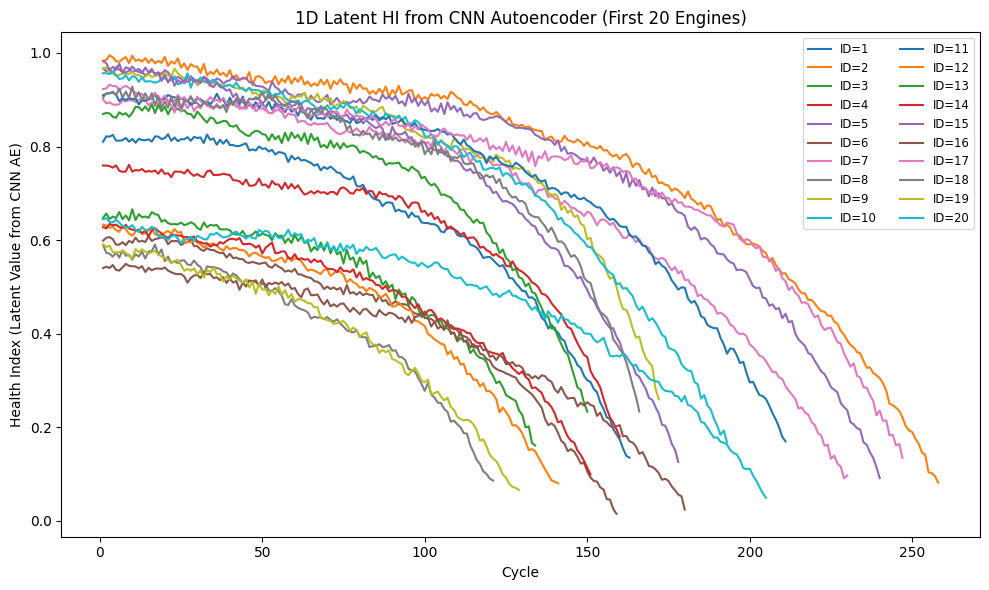

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from keras.models import Model
from keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers import GlobalAveragePooling1D, RepeatVector
from preProcessingDataTurbofan import PreProcessData
import tensorflow as tf
import random

tf.random.set_seed(1)
np.random.seed(1)
random.seed(1)


# -----------------------------
# Load and prepare data
# -----------------------------
column_names = [    "id",   "cycle",    "setting1", "setting2", "setting3",
                    "s1",   "s2",       "s3",       "s4",       "s5",       "s6",   "s7",   "s8",   "s9",   "s10",
                    "s11",  "s12",      "s13",      "s14",      "s15",      "s16",  "s17",  "s18",  "s19",  "s20",  "s21"
                ]
df      = pd.read_csv('~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt', delim_whitespace=True, header=None, names=column_names)
rulDf   = df.groupby('id',sort=False)['cycle'].transform(lambda x: x.max() - x)         # Get RUL

# -----------------------------
# Initialize variables
# -----------------------------
sensors_used    = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
window_size     = 30  # Fixed sequence length
X_windows       = []
engine_ids      = []
start_cycles    = []

# Build sliding windows from each engine
for eng_id in df['id'].unique():
    df_eng      = df[df['id'] == eng_id].sort_values('cycle')
    data_eng    = df_eng[sensors_used].values
    for start in range(0, len(data_eng) - window_size + 1):
        window = data_eng[start : start + window_size]
        X_windows.append(window)
        engine_ids.append(eng_id)
        start_cycles.append(start + 1)

X_windows = np.array(X_windows)  # (N, 30, 14)

# Normalize
N, seq_len, num_feats   = X_windows.shape
X_flat                  = X_windows.reshape(N * seq_len, num_feats)
scaler                  = MinMaxScaler()
X_flat_scaled           = scaler.fit_transform(X_flat)
X_scaled                = X_flat_scaled.reshape(N, seq_len, num_feats)

# -----------------------------
# Encoder block
# -----------------------------
inputs      = Input(shape=(seq_len, num_feats))
x           = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x           = MaxPooling1D(2, padding='same')(x)
x           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer = MaxPooling1D(2, padding='same')(x)
x           = GlobalAveragePooling1D()(lastAELayer)
latent      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# -----------------------------
# Decoder block
# -----------------------------
x           = Dense((seq_len // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seq_len // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(num_feats, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

cnn_ae = Model(inputs, decoded)
cnn_ae.compile(optimizer='adam', loss='mse')
cnn_ae.fit(X_scaled, X_scaled, epochs=20, batch_size=128, validation_split=0.1, verbose=1)


# Extract latent HI values
encoder = Model(    inputs  =   cnn_ae.input,
                    outputs =   [cnn_ae.get_layer('lastAELayer').output, 
                                 cnn_ae.get_layer('latent').output],
                                name="encoder_submodel")
_, hi_values   = encoder.predict(X_scaled).flatten()

# Normalize HI (optional)
hi_values = (hi_values - hi_values.min()) / (hi_values.max() - hi_values.min())

# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id': engine_ids,
    'cycle': start_cycles,
    'HI': hi_values
})

# Plot first 20 engines
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:20]:
    df_eng = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


### Create the data system

In [ ]:
from keras.preprocessing.sequence import pad_sequences

def createSystemData(inData, numberOfTrajectories=300, sensors_used=None):
    """
    Returns a dict keyed by 'mode' -> {
       "comp1X": shape (num_trajectories, max_len, num_sensors),
       "comp2X": ...,
       "comp3X": ...,
       "sysRul": shape (num_trajectories,)
    }
    for each mode in [min, max, linear].
    """
    if sensors_used is None:
        sensors_used = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']

    grouped_data = {k: v for k, v in inData.groupby("id")}
    modes        = ["min", "max", "linear"]
    createdData  = {}

    # For each mode, pick random 3-IDs for each system trajectory
    for curMode in modes:
        selected_ids = np.array([
            np.random.choice(np.arange(1,101), size=3, replace=False) 
            for _ in range(numberOfTrajectories)
        ])

        # Build comp1_df, comp2_df, comp3_df
        comp1_df = pd.concat([
            grouped_data[i].assign(trajectoryID=trajID+1, sysMode=curMode) 
            for trajID, i in enumerate(selected_ids[:,0])
        ], ignore_index=True)
        comp2_df = pd.concat([
            grouped_data[i].assign(trajectoryID=trajID+1, sysMode=curMode) 
            for trajID, i in enumerate(selected_ids[:,1])
        ], ignore_index=True)
        comp3_df = pd.concat([
            grouped_data[i].assign(trajectoryID=trajID+1, sysMode=curMode) 
            for trajID, i in enumerate(selected_ids[:,2])
        ], ignore_index=True)

        # Compute system RUL
        if curMode == 'min':
            rul_series = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).min(axis=1)
        elif curMode == 'max':
            rul_series = pd.concat([comp1_df["rul"], comp2_df["rul"], comp3_df["rul"]], axis=1).max(axis=1)
        else:
            # linear => min( max(rul1,rul2), rul3 )
            # or whichever approach you used
            rul_series = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)

        # group by trajectoryID => gather arrays
        comp1X_list, comp2X_list, comp3X_list, sysRUL_list = [], [], [], []

        uniqueTIDs = comp1_df["trajectoryID"].unique()
        sensors_ct = len(sensors_used)

        for tid in uniqueTIDs:
            c1_traj = comp1_df[comp1_df["trajectoryID"]==tid].sort_values("cycle")
            c2_traj = comp2_df[comp2_df["trajectoryID"]==tid].sort_values("cycle")
            c3_traj = comp3_df[comp3_df["trajectoryID"]==tid].sort_values("cycle")

            arr_c1 = c1_traj[sensors_used].values
            arr_c2 = c2_traj[sensors_used].values
            arr_c3 = c3_traj[sensors_used].values

            # Pick final row for system RUL
            idx_c1      = c1_traj.index
            final_idx   = idx_c1[-1]
            final_sys_rul = rul_series.loc[final_idx]  # or however you prefer

            # Pad to same length
            max_len = max(arr_c1.shape[0], arr_c2.shape[0], arr_c3.shape[0])

            # pad
            p1 = pad_sequences([arr_c1], maxlen=max_len, dtype='float32', 
                               padding='post', truncating='post', value=0.0)
            p2 = pad_sequences([arr_c2], maxlen=max_len, dtype='float32',
                               padding='post', value=0.0)
            p3 = pad_sequences([arr_c3], maxlen=max_len, dtype='float32',
                               padding='post', value=0.0)

            comp1X_list.append(p1[0])
            comp2X_list.append(p2[0])
            comp3X_list.append(p3[0])
            sysRUL_list.append(final_sys_rul)

        # stack
        comp1X_arr = np.array(comp1X_list)  # (num_trajectories, max_len, sensors_ct)
        comp2X_arr = np.array(comp2X_list)
        comp3X_arr = np.array(comp3X_list)
        sysRUL_arr = np.array(sysRUL_list).reshape(-1,1)

        # store
        createdData[curMode] = {
            "comp1X": comp1X_arr,
            "comp2X": comp2X_arr,
            "comp3X": comp3X_arr,
            "sysRUL": sysRUL_arr
        }

    return createdData

# Example usage:
system_data = createSystemData(
    inData=df,
    numberOfTrajectories=300,
    sensors_used=sensors_used
)
# system_data now has: system_data["min"], system_data["max"], system_data["linear"]


### System model

In [ ]:
for layer in encoder.layers:
    layer.trainable = False

In [ ]:
input1              = Input(shape=(seq_len, num_feats))
input2              = Input(shape=(seq_len, num_feats))
input3              = Input(shape=(seq_len, num_feats))

m1              = Masking(mask_value=0.0)(input1)  # if you used 0.0 as pad
m2              = Masking(mask_value=0.0)(input2)  # if you used 0.0 as pad
m3              = Masking(mask_value=0.0)(input3)  # if you used 0.0 as pad

inputRUL1, inputHI1 = encoder(m1)
inputRUL2, inputHI2 = encoder(m2)
inputRUL3, inputHI3 = encoder(m3)

# inputRUL1   = Input(shape=(8, 16),     name = "lastLayerAEComponent1")
# inputRUL2   = Input(shape=(8, 16),     name = "lastLayerAEComponent2")
# inputRUL3   = Input(shape=(8, 16),     name = "lastLayerAEComponent3")

# inputHI1    = Input(shape=(1,),     name = "compHI1")
# inputHI2    = Input(shape=(1,),     name = "compHI2")
# inputHI3    = Input(shape=(1,),     name = "compHI3")


flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

print(f"The shape of hiSelectionInput {hiSelectionInput.shape}")
# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection
print(f"The shape of multiplied matrix {hiMatrixOutput.shape}")

# ------------------------------
# Create min, max and linear HI
# ------------------------------
concatenatedHiInput = Concatenate(axis=-1)([inputHI1, inputHI2, inputHI3])
minSysHi            = Minimum()([inputHI1, inputHI2, inputHI3])
maxSysHi            = Maximum()([inputHI1, inputHI2, inputHI3]) 
linearSysHi         = Minimum()([Maximum()([inputHI1, inputHI2]), inputHI3])


print(f"The shape of min, max and linear HI {minSysHi.shape, maxSysHi.shape, linearSysHi.shape}")

sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
print(f"The shape after concatenation {sysConcatenatedHi.shape}")
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])

print(f"The shape after multiplying with mask {selected_HI.shape}")
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)
# sysHi               = linearSysHi

print(f"The shape of HI after reducing dimension {sysHi.shape}")
# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
# concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2])
rulLayer1   = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2   = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3   = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4   = Concatenate(axis=-1)([rulLayer3, sysHi])
rul         = tf.keras.layers.Dense(1, activation='linear')(rulLayer4)

# Create the model
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(   optimizer='adam',   loss={
                                            "Selection_Output": "categorical_crossentropy",  # no label => 0 weight
                                            "Final_HI":         "mse",                       # no label => 0 weight
                                            "RUL_Output":       "mse"
                                            },
                                        loss_weights={
                                            "Selection_Output": 0.0, 
                                            "Final_HI":         0.0,
                                            "RUL_Output":       1.0
                                            })
sysModel.summary()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Reshape, ZeroPadding1D,
    GlobalAveragePooling1D, Flatten, Lambda, Concatenate, Multiply, Minimum, Maximum, LSTM
)
from sklearn.preprocessing import MinMaxScaler

###############################################################################
# 1) LOAD AND PREPARE DATA (100 trajectories)
###############################################################################

# Example column setup
column_names = [
    "id", "cycle", "setting1", "setting2", "setting3",
    "s1","s2","s3","s4","s5","s6","s7","s8","s9","s10",
    "s11","s12","s13","s14","s15","s16","s17","s18","s19","s20","s21"
]
df = pd.read_csv(
    '~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt',
    delim_whitespace=True, header=None, names=column_names
)

# Example "good sensors"
sensors_used = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
num_feats = len(sensors_used)
seq_len   = 30

# Compute RUL for each row
df['rul'] = df.groupby('id', sort=False)['cycle'].transform(lambda x: x.max() - x)

# Build sliding windows for AE training
X_windows = []
for eng_id in df['id'].unique():
    df_eng   = df[df['id'] == eng_id].sort_values('cycle')
    data_eng = df_eng[sensors_used].values
    # slide
    for start in range(0, len(data_eng) - seq_len + 1):
        window = data_eng[start : start + seq_len]
        X_windows.append(window)

X_windows = np.array(X_windows)  # shape (N,30,14)

# Scale
N = X_windows.shape[0]
X_flat = X_windows.reshape(-1, num_feats)
scaler = MinMaxScaler()
X_flat_scaled = scaler.fit_transform(X_flat)
X_scaled = X_flat_scaled.reshape(N, seq_len, num_feats)

###############################################################################
# 2) TRAIN THE 1D CNN AUTOENCODER (Exactly your code)
###############################################################################

inputs = Input(shape=(seq_len, num_feats))
x = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x = MaxPooling1D(2, padding='same')(x)
x = Conv1D(16, 3, activation='relu', padding='same')(x)
x = MaxPooling1D(2, padding='same')(x)
# shape is now roughly (None, 8,16) with 'same' padding

x_gap = GlobalAveragePooling1D()(x)  # shape (None,16)

latent = Dense(1, name='latent')(x_gap)  # single-scalar HI

# Decoder from latent
# original code says: x = Dense((seq_len // 4) * 16, activation='relu')(latent)
# but we have 8 in length, so let's do 8*16=128
x_dec = Dense(8*16, activation='relu')(latent)  # 128
x_dec = Reshape((8,16))(x_dec)                  # (None,8,16)
x_dec = UpSampling1D(2)(x_dec)                  # (None,16,16)
x_dec = Conv1D(32, 3, activation='relu', padding='same')(x_dec)  # (16,32)
x_dec = UpSampling1D(2)(x_dec)                  # (None,32,32)

# slice or pad to get length=30
def slice_to_30(t):
    return t[:, :30, :]
x_dec = Lambda(slice_to_30)(x_dec)               # (None,30,32)

decoded = Conv1D(num_feats, 3, activation='linear', padding='same')(x_dec)  # (30,14)

cnn_ae = Model(inputs, decoded)
cnn_ae.compile(optimizer='adam', loss='mse')
cnn_ae.summary()

# Train
cnn_ae.fit(X_scaled, X_scaled, 
           epochs=5,  # put more epochs in practice
           batch_size=64,
           validation_split=0.1)

# Build a separate "encoder" sub-model that outputs the 16-dim from x_gap plus the 1-dim latent
encoder = Model(
    inputs=cnn_ae.input,
    outputs=[x_gap, latent]  # shapes: (None,16), (None,1)
)
encoder.summary()

###############################################################################
# 3) FREEZE THE ENCODER (so we don't retrain it in the system model)
###############################################################################
for layer in encoder.layers:
    layer.trainable = False

###############################################################################
# 4) CREATE SYSTEM DATA (3 components => system RUL)
###############################################################################
# Here you'd do your "createSystemData(...)". We'll just do a dummy example:
# Suppose we pick random sets of 3 IDs, each with 300 system trajectories,
#   then we define system RUL = min / max / linear of the 3 RUL's 
#   (like your function).
# We'll skip the full detail and just show the final arrays we need:
#
# For each system trajectory, we'll have:
#   - comp1's last 30x14 => pass to encoder => yields shape(16) + shape(1)
#   - comp2's last 30x14 => ...
#   - comp3's last 30x14 => ...
#   - final label => system RUL
#
# We'll store them in arrays for training the system model.

# For illustration, let's produce random arrays:
num_system_samples = 500  # e.g. 500 system-level examples
all_compFeat1 = np.zeros((num_system_samples, 4,4))  # after we reshape (16->(4,4))
all_compFeat2 = np.zeros((num_system_samples, 4,4))
all_compFeat3 = np.zeros((num_system_samples, 4,4))
all_compHI1   = np.zeros((num_system_samples,1))
all_compHI2   = np.zeros((num_system_samples,1))
all_compHI3   = np.zeros((num_system_samples,1))
all_sysRUL    = np.zeros((num_system_samples,1))

# Real code:
#   for i in range(num_system_samples):
#       # pick 3 random engines or whatever
#       # get their final 30x14 windows
#       # pass each to encoder -> 16-dim,1-dim
#       # reshape(16)->(4,4)
#       # store in all_compFeat1[i], all_compHI1[i]
#       # ...
#       # define system RUL by min/max/linear or so
#
# We'll just fill with random values:
np.random.seed(0)
all_compFeat1 = np.random.rand(num_system_samples, 4,4)
all_compFeat2 = np.random.rand(num_system_samples, 4,4)
all_compFeat3 = np.random.rand(num_system_samples, 4,4)
all_compHI1   = np.random.rand(num_system_samples,1)
all_compHI2   = np.random.rand(num_system_samples,1)
all_compHI3   = np.random.rand(num_system_samples,1)
all_sysRUL    = np.random.rand(num_system_samples,1) * 150  # random RUL up to 150

###############################################################################
# 5) BUILD THE SYSTEM MODEL (min/max/linear + LSTM over (4,4) x 3 comps)
###############################################################################

# The shape is (4,4) for each "lastLayerAEComponent"
# The shape is (1,) for each "compHI"
inputRUL1 = Input(shape=(4,4), name="lastLayerAEComponent1")
inputRUL2 = Input(shape=(4,4), name="lastLayerAEComponent2")
inputRUL3 = Input(shape=(4,4), name="lastLayerAEComponent3")

inputHI1  = Input(shape=(1,),  name="compHI1")
inputHI2  = Input(shape=(1,),  name="compHI2")
inputHI3  = Input(shape=(1,),  name="compHI3")

# ---- The “selection” network: flatten + dense -> 3 logits -> softmax
flat1 = Flatten()(inputRUL1)
flat2 = Flatten()(inputRUL2)
flat3 = Flatten()(inputRUL3)
sel_in = Concatenate(axis=-1)([flat1, flat2, flat3])
x = Dense(24, activation='relu')(sel_in)
x = Dense(16, activation='relu')(x)
selection_logits = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput   = Lambda(lambda z: tf.nn.softmax(z), name="Selection_Output")(selection_logits)
# shape (None,3)

# ---- min, max, linear of the 3 compHIs
minSysHi    = Minimum()([inputHI1, inputHI2, inputHI3])
maxSysHi    = Maximum()([inputHI1, inputHI2, inputHI3])
linearSysHi = Minimum()([Maximum()([inputHI1, inputHI2]), inputHI3])

sysConcatenatedHi = Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
# shape (None,3)

selected_HI = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
sysHi = Lambda(lambda zz: tf.reduce_sum(zz, axis=-1, keepdims=True),
               name="Final_HI")(selected_HI)  # shape (None,1)

# ---- LSTM part across all 3 comp features
# We'll stack them along time dimension => shape (None,12,4)
concatRUL = Concatenate(axis=1)([inputRUL1, inputRUL2, inputRUL3])
rulLayer1 = LSTM(32, return_sequences=True)(concatRUL)  # shape (None,12,32)
rulLayer2 = LSTM(16, return_sequences=True)(rulLayer1)  # shape (None,12,16)
rulLayer3 = LSTM(3,  return_sequences=False)(rulLayer2) # shape (None,3)

# combine with sysHi
rulLayer4 = Concatenate(axis=-1)([rulLayer3, sysHi])    # shape (None,4)
rulOut    = Dense(1, activation='linear', name="RUL_Output")(rulLayer4)

# final system model
system_model = Model(
    inputs=[inputRUL1, inputRUL2, inputRUL3, inputHI1, inputHI2, inputHI3],
    outputs=[hiMatrixOutput, sysHi, rulOut]
)

# compile
system_model.compile(
    optimizer='adam',
    loss={
      "Selection_Output": "categorical_crossentropy",  # if you have ground-truth mode
      "Final_HI":         "mse",                       # if you have system HI label
      "RUL_Output":       "mse"                        # main RUL label
    },
    loss_weights={
      "Selection_Output": 0.0,  # if you don't have real mode labels, set to 0
      "Final_HI":         0.0,  # if you don't have ground truth system HI, set to 0
      "RUL_Output":       1.0   # or 1.0 for emphasis
    }
)

system_model.summary()

###############################################################################
# 6) TRAIN THE SYSTEM MODEL
###############################################################################

# We only have real labels for RUL here. 
# (No real label for which mode was chosen, nor for the system HI).
# So we can feed dummy arrays for those two outputs, or just set their weight=0.

# Prepare dict of inputs
train_inputs = {
  "lastLayerAEComponent1": all_compFeat1,
  "lastLayerAEComponent2": all_compFeat2,
  "lastLayerAEComponent3": all_compFeat3,
  "compHI1": all_compHI1,
  "compHI2": all_compHI2,
  "compHI3": all_compHI3
}
# Prepare dict of outputs
train_outputs = {
  "Selection_Output": np.zeros((num_system_samples, 3)),  # dummy
  "Final_HI":         np.zeros((num_system_samples, 1)),  # dummy
  "RUL_Output":       all_sysRUL
}

history = system_model.fit(
    x=train_inputs,
    y=train_outputs,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

###############################################################################
# 7) INFERENCE: GET THE SYSTEM HI
###############################################################################
# At inference, "system_model.predict()" returns [Selection_Output, Final_HI, RUL_Output].
# The second item in that list is the system HI (the combined min/max/linear scalar).
###############################################################################

preds = system_model.predict(train_inputs)
pred_selection    = preds[0]  # shape (N,3)  => the softmax distribution over min/max/linear
pred_systemHI     = preds[1]  # shape (N,1)  => the chosen system HI
pred_rul          = preds[2]  # shape (N,1)  => final RUL

print("System HI shape:", pred_systemHI.shape)
print("Some example system HIs:", pred_systemHI[:10].flatten())


Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 30, 14)]          0         
                                                                 
 conv1d_4 (Conv1D)           (None, 30, 32)            1376      
                                                                 
 max_pooling1d_2 (MaxPooling  (None, 15, 32)           0         
 1D)                                                             
                                                                 
 conv1d_5 (Conv1D)           (None, 15, 16)            1552      
                                                                 
 max_pooling1d_3 (MaxPooling  (None, 8, 16)            0         
 1D)                                                             
                                                                 
 global_average_pooling1d_1   (None, 16)               0   

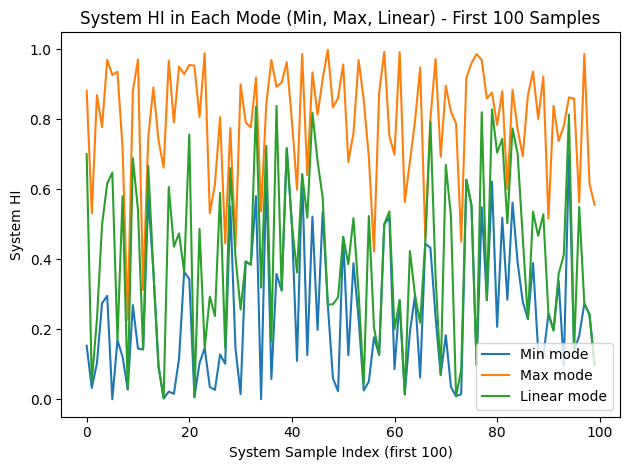

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Suppose you have the arrays:
#  all_compHI1.shape -> (N,1)
#  all_compHI2.shape -> (N,1)
#  all_compHI3.shape -> (N,1)
# for some total of N system samples.

# For demonstration, let's say:
num_samples = 100  # how many to show
idxs = range(num_samples)

# Flatten each to 1-D for easier math
hi1 = all_compHI1[:num_samples, 0]  # shape (num_samples,)
hi2 = all_compHI2[:num_samples, 0]
hi3 = all_compHI3[:num_samples, 0]

# Calculate each mode
minHI = np.minimum(hi1, np.minimum(hi2, hi3))
maxHI = np.maximum(hi1, np.maximum(hi2, hi3))
# linear = min( max(HI1,HI2), HI3 )
linearHI = np.minimum(np.maximum(hi1, hi2), hi3)

# Plot all three on the same figure
plt.figure()
plt.plot(idxs, minHI,    label='Min mode')
plt.plot(idxs, maxHI,    label='Max mode')
plt.plot(idxs, linearHI, label='Linear mode')

plt.xlabel("System Sample Index (first 100)")
plt.ylabel("System HI")
plt.title("System HI in Each Mode (Min, Max, Linear) - First 100 Samples")
plt.legend()
plt.tight_layout()
plt.show()
